In [133]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import datetime
from sklearn.feature_selection import VarianceThreshold

In [135]:
res_data=pd.read_csv('/content/drive/MyDrive/Machine learning files/datasets/restaurant_customer_potential_raw.csv')
res_data.head()


,customer_id,age,gender,area_suburb,household_size,income_bracket,days_since_signup,app_sessions_last_30d,menu_views_last_30d,avg_session_minutes,...,avg_party_size,dietary_pref,preferred_time_slot,preferred_day,discount_used_before,loyalty_member,review_left_before,acquisition_channel,promo_code_used,customer_potential_class
0,CUST_10521,39,female,Newton Park,3,NaN,572.0,1.0,1.0,0.68,...,1.0,HALAAL,dinner,both,0,0,0,google,0,Non-Potential Customer
1,CUST_10737,43,male,Kabega Park,1,Low,179.0,13.0,28.0,5.73,...,5.0,NaN,afternoon,weekday,0,1,0,google,0,high potential customer
2,CUST_10740,32,Male,Lorraine,1,R30k-R60k,524.0,5.0,5.0,5.52,...,4.0,kosher,lunch,both,1,0,0,IG,0,Moderate Potential Customer
3,CUST_10660,27,Non-binary,Humewood,6,NaN,926.0,0.0,0.0,2.16,...,NaN,none,lunch,weekend,0,0,0,walk-in,1,Non-Potential Customer
4,CUST_10411,35,Non-binary,WALMER,4,NaN,53.0,20.0,47.0,5.47,...,1.0,none,lunch,both,No,Y,1,referral,0,2


DATA CLEANING PIPELINE

In [136]:
res_data.columns

Index(['customer_id', 'age', 'gender', 'area_suburb', 'household_size',
       'income_bracket', 'days_since_signup', 'app_sessions_last_30d',
       'menu_views_last_30d', 'avg_session_minutes', 'last_activity_days_ago',
       'emails_opened_last_30d', 'sms_clicks_last_30d',
       'push_notifications_opened', 'num_orders_total', 'num_orders_last_30d',
       'avg_order_value', 'days_since_last_order', 'favourite_cuisine',
       'orders_delivery_vs_dinein_ratio', 'avg_party_size', 'dietary_pref',
       'preferred_time_slot', 'preferred_day', 'discount_used_before',
       'loyalty_member', 'review_left_before', 'acquisition_channel',
       'promo_code_used', 'customer_potential_class'],
      dtype='object')

In [137]:
res_data=res_data.drop('customer_id',axis=1)

In [138]:

res_data['age']=res_data['age'].str.replace('yrs','').astype(float)

In [139]:
res_data['gender'].unique()

array(['female', 'male', 'Male', 'Non-binary', nan, 'Prefer not to say',
       'F', 'Female', 'M'], dtype=object)

In [140]:
gender_map={'female':'Female','male':'Male',
            'M':'Male','F':'Female'}
res_data['gender']=res_data['gender'].replace(gender_map)



In [141]:
pref_map={'HALAAL':'Halaal','vegetarian':'vegan',
          'halaal':'Halaal','veg':'vegan'}
res_data['dietary_pref']=res_data['dietary_pref'].replace(pref_map)

In [142]:
slot_map={'DINNER':'dinner','late night':'dinner',
          'Lunch':'lunch','late-night':'dinner'}
res_data['preferred_time_slot']=res_data['preferred_time_slot'].replace(slot_map)

In [143]:
prefered_daymap={'WEEKEND':'weekend','Weekday':'weekday',
                 }
res_data['preferred_day']=res_data['preferred_day'].replace(prefered_daymap)

In [144]:
loyalty_map={'Y':'yes','N':'no',}

res_data['loyalty_member']=res_data['loyalty_member'].replace(loyalty_map)

In [145]:

channel_map={'Google':'google','IG':'Instagram',
            'walk-in':'Walk In','Walkin In':'Walk In'}
res_data['acquisition_channel']=res_data['acquisition_channel'].replace(channel_map)


In [146]:
potential_map={'Non-Potential Customer':0,'non-potential customer':0,'Non Potential':0,
               'high potential customer':2,'Moderate Potential Customer':1,'2':2,
               'Hight Potential Customer':2,'Moderate Potential':1,'1':1,
               '0':0,'moderate potential':1,'High Potential':2}
res_data['customer_potential_class']=res_data['customer_potential_class'].map(potential_map)

In [147]:
res_data=pd.get_dummies(res_data,columns=['area_suburb','gender','income_bracket','favourite_cuisine','dietary_pref','preferred_time_slot','preferred_day',
                                 'loyalty_member','discount_used_before','acquisition_channel','promo_code_used'])



In [148]:
res_data['orders_delivery_vs_dinein_ratio']=res_data['orders_delivery_vs_dinein_ratio'].str.replace('70/30','2.33').astype(float)


In [149]:
res_data['household_size']=res_data['household_size'].str.replace('adults','').astype(float)


In [150]:
res_data['avg_session_minutes']=res_data['avg_session_minutes'].str.replace('min','').astype(float)


In [151]:
res_data['avg_order_value']=res_data['avg_order_value'].str.replace('R','').astype(float)

In [152]:
res_data=res_data.dropna()

In [153]:
res_data.head()

,age,household_size,days_since_signup,app_sessions_last_30d,menu_views_last_30d,avg_session_minutes,last_activity_days_ago,emails_opened_last_30d,sms_clicks_last_30d,push_notifications_opened,...,acquisition_channel_Walk In,acquisition_channel_email list,acquisition_channel_flyer,acquisition_channel_google,acquisition_channel_referral,acquisition_channel_unknown,promo_code_used_0,promo_code_used_1,promo_code_used_false,promo_code_used_true
1,43.0,1.0,179.0,13.0,28.0,5.73,6,6.0,2,4,...,False,False,False,True,False,False,True,False,False,False
2,32.0,1.0,524.0,5.0,5.0,5.52,18,1.0,2,0,...,False,False,False,False,False,False,True,False,False,False
4,35.0,4.0,53.0,20.0,47.0,5.47,6,4.0,5,5,...,False,False,False,False,True,False,True,False,False,False
6,52.0,1.0,217.0,7.0,11.0,2.60,17,4.0,2,3,...,False,False,False,False,False,False,True,False,False,False
9,27.0,2.0,265.0,1.0,2.0,2.93,9,4.0,2,1,...,False,False,False,False,False,False,False,True,False,False


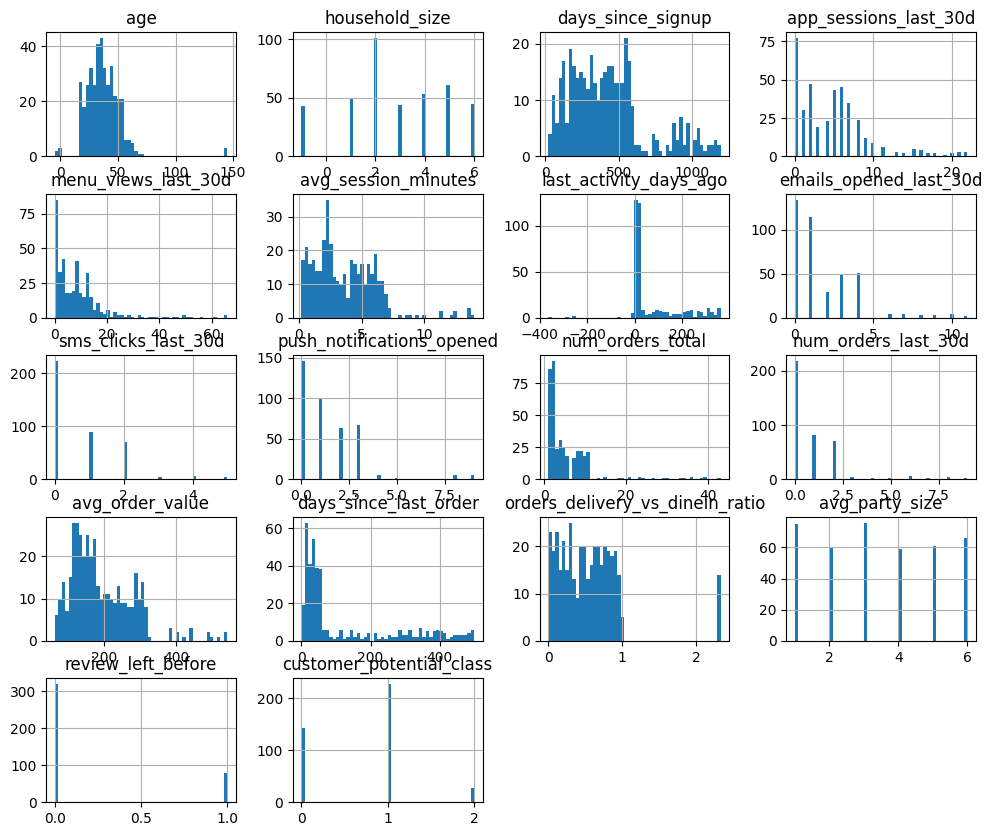

In [154]:
res_data.hist(figsize=(12,10),bins=50)
plt.show()

In [155]:
res_data.columns


Index(['age', 'household_size', 'days_since_signup', 'app_sessions_last_30d',
       'menu_views_last_30d', 'avg_session_minutes', 'last_activity_days_ago',
       'emails_opened_last_30d', 'sms_clicks_last_30d',
       'push_notifications_opened', 'num_orders_total', 'num_orders_last_30d',
       'avg_order_value', 'days_since_last_order',
       'orders_delivery_vs_dinein_ratio', 'avg_party_size',
       'review_left_before', 'customer_potential_class',
       'area_suburb_ Lorraine', 'area_suburb_Central',
       'area_suburb_Greenacres', 'area_suburb_Humewood',
       'area_suburb_Kabega Park', 'area_suburb_Lorraine',
       'area_suburb_Mill Park', 'area_suburb_Newton Park',
       'area_suburb_Summerstrand', 'area_suburb_Sunnyside',
       'area_suburb_Unknown', 'area_suburb_WALMER ', 'area_suburb_Walmer',
       'area_suburb_newton park', 'area_suburb_summerstrand', 'gender_Female',
       'gender_Male', 'gender_Non-binary', 'gender_Prefer not to say',
       'income_bracket_Hig

In [156]:
y=res_data.iloc[:,17]
res_data=res_data.drop('customer_potential_class',axis=1)

In [157]:
x=res_data.iloc[:,0:]
x.head()

,age,household_size,days_since_signup,app_sessions_last_30d,menu_views_last_30d,avg_session_minutes,last_activity_days_ago,emails_opened_last_30d,sms_clicks_last_30d,push_notifications_opened,...,acquisition_channel_Walk In,acquisition_channel_email list,acquisition_channel_flyer,acquisition_channel_google,acquisition_channel_referral,acquisition_channel_unknown,promo_code_used_0,promo_code_used_1,promo_code_used_false,promo_code_used_true
1,43.0,1.0,179.0,13.0,28.0,5.73,6,6.0,2,4,...,False,False,False,True,False,False,True,False,False,False
2,32.0,1.0,524.0,5.0,5.0,5.52,18,1.0,2,0,...,False,False,False,False,False,False,True,False,False,False
4,35.0,4.0,53.0,20.0,47.0,5.47,6,4.0,5,5,...,False,False,False,False,True,False,True,False,False,False
6,52.0,1.0,217.0,7.0,11.0,2.60,17,4.0,2,3,...,False,False,False,False,False,False,True,False,False,False
9,27.0,2.0,265.0,1.0,2.0,2.93,9,4.0,2,1,...,False,False,False,False,False,False,False,True,False,False


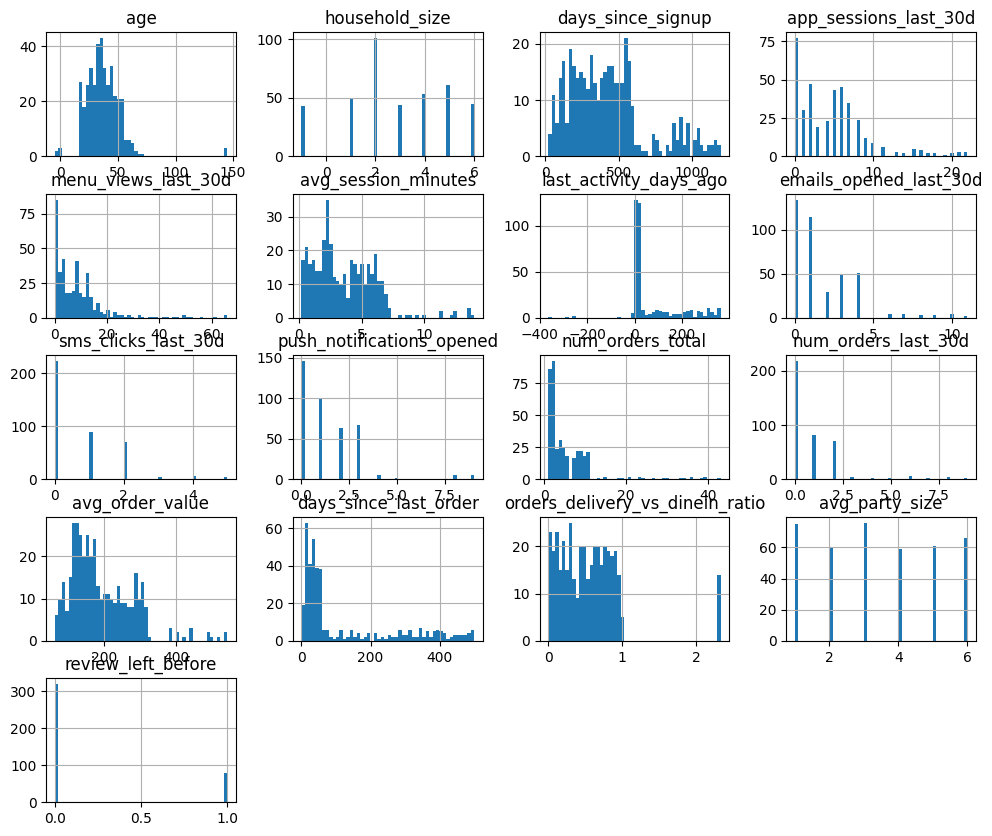

In [158]:
x.hist(figsize=(12,10),bins=50)
plt.show()

DATA SPLITING AND SCALING

In [159]:
#data splits
xtrain,xtemp,ytrain,ytemp=train_test_split(x,y,test_size=0.2,random_state=42)
xtest,xdev,ytest,ydev=train_test_split(xtemp,ytemp,test_size=0.5,random_state=42)

In [160]:
#scaler and varience
sel=VarianceThreshold()
scaler=StandardScaler()
xtrain_scaled=scaler.fit_transform(sel.fit_transform(xtrain))
xtest_scaled=scaler.transform(sel.transform(xtest))
xdev_scaled=scaler.transform(sel.transform(xdev))

In [161]:
#coverting data into tensors
xtrain_tensor=torch.tensor(xtrain_scaled,dtype=torch.float32)
xtest_tensor=torch.tensor(xtest_scaled,dtype=torch.float32)
xdev_tensor=torch.tensor(xdev_scaled,dtype=torch.float32)


ytrain_tensor=torch.tensor(ytrain.values,dtype=torch.long)
ytest_tensor=torch.tensor(ytest.values,dtype=torch.long)
ydev_tensor=torch.tensor(ydev.values,dtype=torch.long)

In [162]:
#tensor datasets
train_tensor=TensorDataset(xtrain_tensor,ytrain_tensor)
test_tensor=TensorDataset(xtest_tensor,ytest_tensor)
dev_tensor=TensorDataset(xdev_tensor,ydev_tensor)

In [163]:
#DATALOADERS

train_loader=DataLoader(train_tensor,batch_size=50,shuffle=True)
test_loader=DataLoader(test_tensor,batch_size=20,shuffle=False)
dev_loader=DataLoader(dev_tensor,batch_size=20,shuffle=False)

In [164]:
xfeatures=xtest_tensor.shape[1]
xfeatures

84

In [165]:
#NEURAL NETWORK ACHITECTURE

class potential_customer(nn.Module):
  def __init__(self,features):
    super().__init__()

    self.layer1=nn.Linear(features,12)
    self.layer2=nn.Linear(12,6)
    self.layer3=nn.Linear(6,3)
    self.relu=nn.ReLU()

  def forward(self,x):
    z1=self.layer1(x)
    a1=self.relu(z1)

    z2=self.layer2(a1)
    a2=self.relu(z2)

    z3=self.layer3(a2)
    a3=z3  #linear activation

    return a3

torch.manual_seed(42)
model=potential_customer(xfeatures)
loss=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=0.001)


In [ ]:
#nn training loop

for epoch in range(1000):
  for xbatch,ybatch in train_loader:
    optimizer.zero_grad()
    prediction1=model(xbatch)
    lossvalue=loss(prediction1,ybatch)
    lossvalue.backward()
    optimizer.step()
  if epoch %100==0:
    print(f'epoch:{epoch} , loss:{lossvalue.item():.2f}')

epoch:0 , loss:1.15
epoch:100 , loss:0.01
epoch:200 , loss:0.00
epoch:300 , loss:0.00
epoch:400 , loss:0.00
epoch:500 , loss:0.00
epoch:600 , loss:0.00
epoch:700 , loss:0.00
epoch:800 , loss:0.00


In [ ]:
#test evaluation
model.eval()
with torch.no_grad():
  for xbatch,ybatch in test_loader:
    prediction2=model(xbatch)
    lossvalue=loss(prediction2,ybatch)
    print(f'loss:{lossvalue.item():.2f}')

In [ ]:
plt.plot(ytest_tensor[:20],label=('True label'),marker='o')
plt.plot(prediction2[:20],label=('prediction'),marker='o')

plt.legend()
plt.xlabel('samples')
plt.ylabel('values')
plt.show()

In [ ]:
#dev evaluation
model.eval()
with torch.no_grad():
  for xbatch,ybatch in dev_loader:
    prediction3=model(xbatch)
    lossvalue=loss(prediction3,ybatch)
    print(f'loss:{lossvalue.item():.2f}')

In [ ]:
plt.plot(ydev_tensor[:20],label=('true label'),marker='o')
plt.plot(prediction3[:20],label=('prediction'),marker='o')

plt.legend()
plt.xlabel('samples')
plt.ylabel('values')
plt.show()